In [1]:
import pathlib 
import numpy as np
import scipy as sp
from matplotlib import pyplot as plt

import el_hd_plasticity.two_photon as nmp
from SessionTools import two_photon as st2p

%load_ext autoreload
%autoreload 2

%matplotlib inline

In [2]:
def plot_single_sess(pp, fig, ax, color):
   
    frame_times = np.array(pp.metadata['frame_times']).mean(axis=1)


    dt = np.diff(frame_times).mean()
    heading = np.angle(np.exp(1j*(-1* pp.voltage_recording_aligned[' Heading'].to_numpy()-np.pi)))
    index = pp.voltage_recording_aligned[' Y/Index'].to_numpy()
    index_bool = index<5
    stim_ons = index_bool[1:] & ~index_bool[:-1]
    sim_on_inds = np.where(stim_ons)[0]

    loc1_inds = sim_on_inds[0::2]
    loc2_inds = sim_on_inds[1::2]


    background = np.squeeze(pp.timeseries['background'][-1,:,:])
    background -= background[:20].mean()
    outer_ring = np.squeeze(pp.timeseries['outer_ring'][-1,:,:]) #- .5*background


    t_before = 5
    t_after = 10

    inds_before = int(t_before/dt)
    inds_after = int(t_after/dt)

    loc1_resp = np.zeros((len(loc1_inds), inds_before+inds_after))
    loc2_resp = np.zeros((len(loc2_inds), inds_before+inds_after))
    background_resp = np.zeros((len(loc1_inds) + len(loc2_inds), inds_before+inds_after))
    for row, loc1_ind in enumerate(loc1_inds):

        _resp = outer_ring[loc1_ind-inds_before:loc1_ind+inds_after]
        baseline = _resp[:inds_before].mean()

        _t = np.arange(-inds_before, inds_after)*dt
        loc1_resp[row, :] = _resp/baseline-1

        _background = background[loc1_ind-inds_before:loc1_ind+inds_after]
        baseline = _background[:inds_before].mean()
        background_resp[row, :] = _background/baseline-1    
        
    for row, loc2_ind in enumerate(loc2_inds):

        _resp = outer_ring[loc2_ind-inds_before:loc2_ind+inds_after]
        baseline = _resp[:inds_before].mean()

        _t = np.arange(-inds_before, inds_after)*dt
        loc2_resp[row, :] = _resp/baseline-1

        _background = background[loc2_ind-inds_before:loc2_ind+inds_after]
        baseline = _background[:inds_before].mean()
        background_resp[len(loc1_inds)+row, :] = _background/baseline-1

    
    mu, sem = loc1_resp.mean(axis=0), sp.stats.sem(loc1_resp, axis=0)
    ax[0].plot(_t, mu, color=color)
    ax[0].fill_between(_t, mu-sem, mu+sem, color=color, alpha=0.5)
    
    

    mu, sem = loc2_resp.mean(axis=0), sp.stats.sem(loc2_resp, axis=0)
    ax[1].plot(_t, mu, color=color)
    ax[1].fill_between(_t, mu-sem, mu+sem, color=color, alpha=0.5)
    
    
  

    # mu, sem = background_resp.mean(axis=0), sp.stats.sem(background_resp, axis=0)
    # ax[2].plot(_t, mu, color=color)
    # ax[2].fill_between(_t, mu-sem, mu+sem, color=color, alpha=0.5)
    


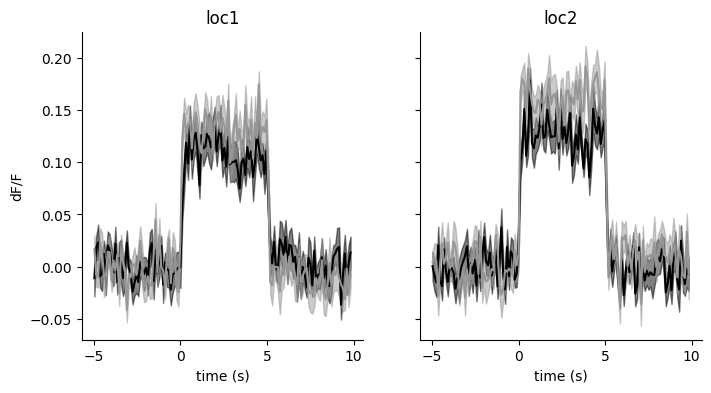

In [6]:
genotype_dir = 'R60D05Gal4_iGABASnFR2_R18B05LexA_CsChrimsontdT/exp'
date = '10_09_2026'
fly = 'fly2'

sessions = [
    # '2loc_flash-001',
    # '2loc_flash_stimloc1-002',
    '2loc_flash-003',
    # '2loc_flash_stimloc2-004',
    '2loc_flash_stimloc2-005'
]

fig, ax = plt.subplots(1,2, figsize=(8,4),sharey=True)
cmap = plt.get_cmap('Greys_r')
for i, sess in enumerate(sessions):
    outdir = pathlib.PurePath(f'/media/mplitt/SSD_storage/2P_scratch/{genotype_dir}/{date}/{fly}/{sess}/preprocess.pkl')
    # print(outdir)
    pp = st2p.preprocessing.EBImagingSession.from_file(outdir)

    
    ax[0].set_title('loc1')
    ax[0].set_xlabel('time (s)')
    ax[0].set_ylabel('dF/F')
    # ax[0].set_ylim([-0.05, .2])

    ax[1].set_title('loc2')
    ax[1].set_xlabel('time (s)')
    # ax[1].set_ylim([-0.05, .2])

    # ax[2].set_title('background')

    for a in ax.flatten():
        a.spines['top'].set_visible(False)
        a.spines['right'].set_visible(False)


    plot_single_sess(pp, fig, ax, color=cmap(i/len(sessions)))

